In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

fc = pd.read_csv("forecast_2017.csv", parse_dates=["date"])
fc = fc.sort_values(["store", "item", "date"]).reset_index(drop=True)
fc["pred"] = fc["pred"].clip(lower=1)
fc["rel_err"] = (fc["sales"] - fc["pred"]) / fc["pred"]

pool = fc[fc["date"] < "2017-07-01"]
win = fc[(fc["date"] >= "2017-07-01") & (fc["date"] <= "2017-07-28")]

pairs = win[["store", "item"]].drop_duplicates().reset_index(drop=True)
print("Pairs:", len(pairs), "| Days in window:", win["date"].nunique())

Pairs: 50 | Days in window: 28


In [2]:
rng = np.random.default_rng(42)
S, D, n = 1000, 28, len(pairs)

pred_arr = np.zeros((n, D))
actual_arr = np.zeros((n, D))
scen = np.zeros((S, n, D))

for i, (s, it) in enumerate(zip(pairs["store"], pairs["item"])):
    w = win[(win["store"] == s) & (win["item"] == it)].sort_values("date")
    pred_arr[i] = w["pred"].values
    actual_arr[i] = w["sales"].values
    errs = pool[(pool["store"] == s) & (pool["item"] == it)]["rel_err"].values
    draws = rng.choice(errs, size=(S, D))
    scen[:, i, :] = np.maximum(0, np.round(pred_arr[i] * (1 + draws)))

print(scen.shape)   # expect (1000, 50, 28)

(1000, 50, 28)


In [3]:
tot_sim = scen.sum(axis=2)            # (S, n) simulated 28-day totals
tot_act = actual_arr.sum(axis=1)      # real 28-day totals
tot_pred = pred_arr.sum(axis=1)

lo, hi = np.percentile(tot_sim, [5, 95], axis=0)
inside = ((tot_act >= lo) & (tot_act <= hi)).mean()

print(f"Real totals inside the simulated 5-95% range: {inside:.0%} of pairs")
print(f"Total forecast: {tot_pred.sum():.0f} | Total actual: {tot_act.sum():.0f}")

Real totals inside the simulated 5-95% range: 82% of pairs
Total forecast: 103002 | Total actual: 103651


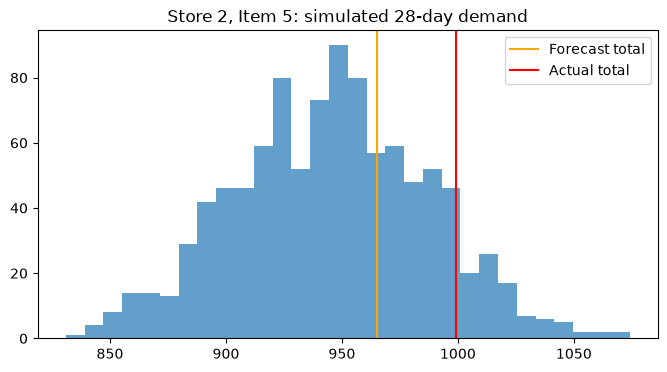

In [4]:
i = 0
plt.figure(figsize=(8, 4))
plt.hist(tot_sim[:, i], bins=30, alpha=0.7)
plt.axvline(tot_pred[i], color="orange", label="Forecast total")
plt.axvline(tot_act[i], color="red", label="Actual total")
plt.title(f"Store {pairs.store[i]}, Item {pairs.item[i]}: simulated 28-day demand")
plt.legend()
plt.show()

In [6]:
np.save("scenarios.npy", scen)
np.save("actual_demand.npy", actual_arr)
np.save("forecast_demand.npy", pred_arr)
pairs.to_csv("pairs.csv", index=False)